# 04 — EDA: análise exploratória

Código espelhado de `RETREINO/02_eda.py`. A view temporária `tbl_eda` foi substituída por `desloc.gold.transacoes_eda`; `distancia` foi renomeada para `distancia_lalo`. As análises univariada, bivariada e multivariada seguem o professor.

**Dependência da aula:** `seaborn` é instalado nas duas células seguintes antes de importar `pairplot` e `heatmap`. Após o reinício do Python, continue a execução a partir da consulta à Gold.


In [1]:
%pip install seaborn==0.13.2

In [2]:
%restart_python

In [3]:
%sql
SELECT * FROM desloc.gold.transacoes_eda LIMIT 2

vlr_pago,dia,dia_semana,mes,hora,periodo,distancia_lalo,duracao
23.97,3,2,11,7,1,4.2078524,12
24.71,23,5,10,9,1,4.3162794,11


In [4]:
df = spark.table("desloc.gold.transacoes_eda").toPandas()

In [5]:
df

,vlr_pago,dia,dia_semana,mes,hora,periodo,distancia_lalo,duracao
0,23.97,3,2,11,7,1,4.207852,12
1,24.71,23,5,10,9,1,4.316279,11
2,23.01,22,4,10,11,1,4.215667,9
3,21.20,18,7,10,18,3,3.400367,11
4,21.74,13,2,10,11,1,3.597638,11
...,...,...,...,...,...,...,...,...
99,24.97,31,6,10,18,3,4.407781,12
100,22.76,31,6,10,19,3,4.015433,11
101,26.54,3,2,11,8,1,4.206109,19
102,26.30,3,2,11,19,3,4.917348,11


### Análise Univariada

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
vlr_pago,104.0,22.817692,3.371668,14.3400,20.792500,23.330000,24.84250,33.120000
dia,104.0,14.567308,9.321407,1.0000,7.000000,13.000000,23.00000,31.000000
dia_semana,104.0,4.269231,1.807378,1.0000,2.750000,4.000000,6.00000,7.000000
mes,104.0,8.182692,2.079789,2.0000,7.000000,8.000000,10.00000,11.000000
hora,104.0,12.990385,3.674882,7.0000,10.000000,13.000000,16.00000,22.000000
periodo,104.0,1.692308,0.711581,1.0000,1.000000,2.000000,2.00000,3.000000
distancia_lalo,104.0,3.849774,0.863909,1.6973,3.373871,4.054581,4.39638,6.293622
duracao,104.0,12.211538,10.319811,6.0000,8.750000,11.000000,13.00000,106.000000


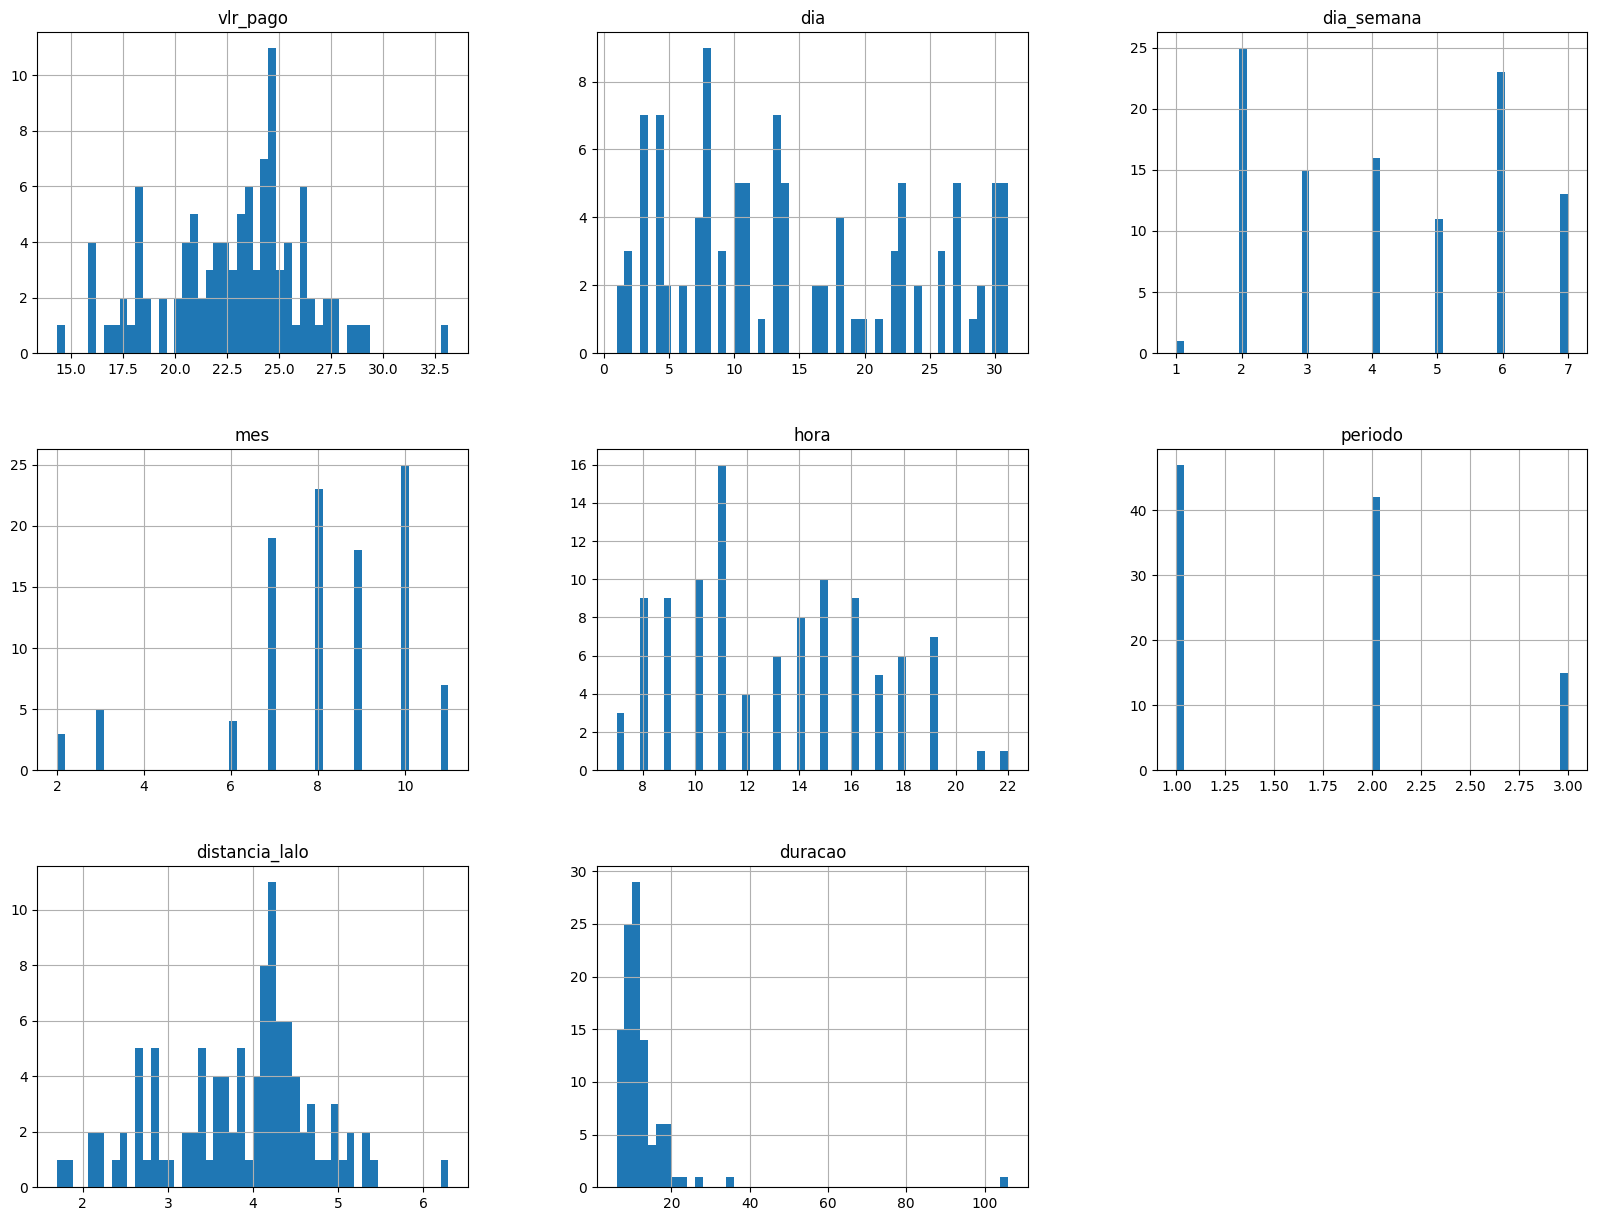

In [7]:
df.hist(bins=50, figsize=(20, 15));

In [8]:
df["mes"].value_counts()

mes
10    25
8     23
7     19
9     18
11     7
3      5
6      4
2      3
Name: count, dtype: int64

In [9]:
df[df["duracao"] > 50]

,vlr_pago,dia,dia_semana,mes,hora,periodo,distancia_lalo,duracao
7,27.0,10,6,10,19,3,4.918842,106


<Axes: >

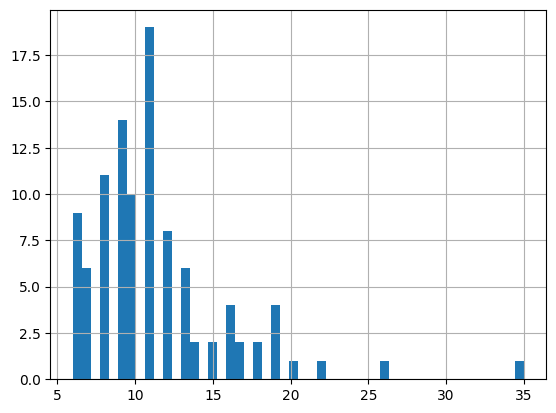

In [10]:
df[df["duracao"] < 50]["duracao"].hist(bins=50)

### Análise Bivariada

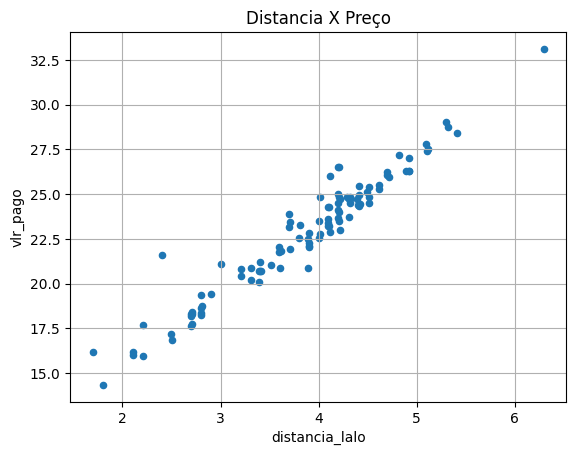

In [11]:
df[["distancia_lalo", "vlr_pago"]].plot(
    kind="scatter", x="distancia_lalo", y="vlr_pago", grid=True,
    title="Distancia X Preço"
);

In [12]:
df[["distancia_lalo", "vlr_pago"]].corr(method="pearson")

,distancia_lalo,vlr_pago
distancia_lalo,1.000000,0.966908
vlr_pago,0.966908,1.000000


In [13]:
df[["dia_semana", "vlr_pago"]].groupby("dia_semana").agg(
    qtd_corridas=("vlr_pago", "count"),
    pct_corridas=("vlr_pago", lambda x: x.count() / df.shape[0] * 100),
    pct_arrecadacao_dia=("vlr_pago", lambda x: x.sum() / df["vlr_pago"].sum() * 100),
    total_arrecadado=("vlr_pago", "sum"),
    media_arrecadado=("vlr_pago", "mean")
)

,qtd_corridas,pct_corridas,pct_arrecadacao_dia,total_arrecadado,media_arrecadado
dia_semana,,,,,
1,1,0.961538,0.674662,16.01,16.010000
2,25,24.038462,24.278984,576.15,23.046000
3,15,14.423077,14.462883,343.21,22.880667
4,16,15.384615,15.606564,370.35,23.146875
5,11,10.576923,10.149429,240.85,21.895455
6,23,22.115385,22.840323,542.01,23.565652
7,13,12.500000,11.987156,284.46,21.881538


In [14]:
df[["periodo", "vlr_pago"]].groupby("periodo").agg(
    qtd_corridas=("vlr_pago", "count"),
    pct_corridas=("vlr_pago", lambda x: x.count() / df.shape[0] * 100),
    pct_arrecadacao_dia=("vlr_pago", lambda x: x.sum() / df["vlr_pago"].sum() * 100),
    total_arrecadado=("vlr_pago", "sum"),
    media_arrecadado=("vlr_pago", "mean")
)

,qtd_corridas,pct_corridas,pct_arrecadacao_dia,total_arrecadado,media_arrecadado
periodo,,,,,
1,47,45.192308,45.707194,1084.65,23.077660
2,42,40.384615,38.727539,919.02,21.881429
3,15,14.423077,15.565266,369.37,24.624667


### Análise multivariada

In [15]:
from seaborn import pairplot, heatmap

In [16]:
heatmap(df.corr(), annot=True)

---------------------------------------------------------------------------
NameError                                 Traceback (most recent call last)
File <command-8288229524473324>, line 1
----> 1 heatmap(df.corr(), annot=True)

NameError: name 'df' is not defined

In [17]:
pairplot(df)

## Explicabilidade (XAI) e limite de negócio
Este é um cabeçalho explicativo; nenhum código de XAI foi acrescentado ao roteiro do professor. `duracao` e a hora de entrega só são conhecidos após a corrida; a tabela não inclui previsões do modelo atual para avaliar drift ou erro em produção.